# Rideshare Pricing — Exploratory Data Analysis

**Research question:** *What are the key factors associated with rideshare pricing, and how important is each factor in explaining price variation?*

## Purpose of this notebook

This is the exploration stage of the project. We examine the original Uber/Lyft quote data, identify data-quality problems, describe how fares vary, and use those observations to justify an initial modeling plan. The statistical importance rankings are calculated later.

### 1. Import libraries and load the dataset

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

DATA_DIR = Path("data") if Path("data").is_dir() else Path("../../data")
df = pd.read_csv(DATA_DIR / "rideshare_kaggle.csv")
df.head()

,id,timestamp,hour,day,month,datetime,timezone,source,destination,cab_type,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,1.544953e+09,9,16,12,2018-12-16 09:30:07,America/New_York,Haymarket Square,North Station,Lyft,...,0.1276,1544979600,39.89,1545012000,43.68,1544968800,33.73,1545012000,38.07,1544958000
1,4bd23055-6827-41c6-b23b-3c491f24e74d,1.543284e+09,2,27,11,2018-11-27 02:00:23,America/New_York,Haymarket Square,North Station,Lyft,...,0.1300,1543251600,40.49,1543233600,47.30,1543251600,36.20,1543291200,43.92,1543251600
2,981a3613-77af-4620-a42a-0c0866077d1e,1.543367e+09,1,28,11,2018-11-28 01:00:22,America/New_York,Haymarket Square,North Station,Lyft,...,0.1064,1543338000,35.36,1543377600,47.55,1543320000,31.04,1543377600,44.12,1543320000
3,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,1.543554e+09,4,30,11,2018-11-30 04:53:02,America/New_York,Haymarket Square,North Station,Lyft,...,0.0000,1543507200,34.67,1543550400,45.03,1543510800,30.30,1543550400,38.53,1543510800
4,e0126e1f-8ca9-4f2e-82b3-50505a09db9a,1.543463e+09,3,29,11,2018-11-29 03:49:20,America/New_York,Haymarket Square,North Station,Lyft,...,0.0001,1543420800,33.10,1543402800,42.18,1543420800,29.11,1543392000,35.75,1543420800


### 2. Dataset structure and data quality

In [ ]:
print("Dataset dimensions (rows, columns):", df.shape)
print("\nColumns:\n", df.columns.tolist())
print("\nData types:")
df.info()

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
print("\nVariables with missing values:\n", missing[missing.missing_count > 0])

print("\nDuplicate quote IDs:", df["id"].duplicated().sum())
print("\nMissing price records by platform/product:\n",
      df.loc[df["price"].isna()].groupby(["cab_type", "name"]).size())

Dataset dimensions (rows, columns): (693071, 57)

Columns:
 ['id', 'timestamp', 'hour', 'day', 'month', 'datetime', 'timezone', 'source', 'destination', 'cab_type', 'product_id', 'name', 'price', 'distance', 'surge_multiplier', 'latitude', 'longitude', 'temperature', 'apparentTemperature', 'short_summary', 'long_summary', 'precipIntensity', 'precipProbability', 'humidity', 'windSpeed', 'windGust', 'windGustTime', 'visibility', 'temperatureHigh', 'temperatureHighTime', 'temperatureLow', 'temperatureLowTime', 'apparentTemperatureHigh', 'apparentTemperatureHighTime', 'apparentTemperatureLow', 'apparentTemperatureLowTime', 'icon', 'dewPoint', 'pressure', 'windBearing', 'cloudCover', 'uvIndex', 'visibility.1', 'ozone', 'sunriseTime', 'sunsetTime', 'moonPhase', 'precipIntensityMax', 'uvIndexTime', 'temperatureMin', 'temperatureMinTime', 'temperatureMax', 'temperatureMaxTime', 'apparentTemperatureMin', 'apparentTemperatureMinTime', 'apparentTemperatureMax', 'apparentTemperatureMaxTime']

Data

#### EDA takeaway — data quality and the target

- **Size and scope:** The raw file contains **693,071 quote records and 57 columns**. Each observation represents a quoted fare, rather than a confirmed completed trip.
- **Missing outcome:** `price` is missing for **55,095 records (7.95%)**; all of these belong to the **Uber Taxi** product. A fare cannot be reliably reconstructed from the other columns, so these records will be **excluded from fare modeling** rather than filled with invented values. As a result, this project does **not** assess Uber Taxi fares.
- **Duplicates:** There are **no duplicate values of `id`** in the raw data. The SQL preprocessing step will still include an ID-based deduplication safeguard.
- **Too many raw features:** Several of the 57 columns are identifiers, alternative summaries of the same weather conditions, or timestamps of daily weather extrema. We should make a deliberate predictor shortlist rather than feed every column into the model.

**Decision for the next stage:** Use `price` as the outcome, preserve the original CSV for reproducibility, and perform actual cleaning in `preprocessing.sql`. The filtering in this notebook is for EDA only.

### 3. Prepare observations with known prices

In [ ]:
cols = [
    "timestamp", "cab_type", "name", "source", "destination",
    "price", "distance", "surge_multiplier", "temperature",
    "apparentTemperature", "precipIntensity", "precipProbability",
    "humidity", "windSpeed", "windGust", "visibility", "short_summary"
]
data = df.loc[df["price"].notna(), cols].copy()

# Use the Unix timestamp to derive Boston's local date and hour.
data["local_datetime"] = pd.to_datetime(
    data["timestamp"], unit="s", utc=True
).dt.tz_convert("America/New_York")
data["local_hour"] = data["local_datetime"].dt.hour
data["weekday"] = data["local_datetime"].dt.day_name()

print("Priced observations:", len(data))
print("Date range:", data["local_datetime"].min(), "to", data["local_datetime"].max())
print("\nObservations by platform:\n", data["cab_type"].value_counts())
print("Unique pickup locations:", data["source"].nunique())
print("Unique destinations:", data["destination"].nunique())
print("Unique origin-destination pairs:", data[["source", "destination"]].drop_duplicates().shape[0])

Priced observations: 637976
Date range: 2018-11-25 22:40:46-05:00 to 2018-12-18 14:15:11-05:00

Observations by platform:
 cab_type
Uber    330568
Lyft    307408
Name: count, dtype: int64
Unique pickup locations: 12
Unique destinations: 12
Unique origin-destination pairs: 72


#### EDA takeaway — observations and coverage

After excluding rows without a known price, **637,976 priced quotes** remain: **330,568 Uber** and **307,408 Lyft**. The data covers **12 pickup locations, 12 destinations, and 72 observed origin–destination pairs**. The timestamp-derived local range is **November 25–December 18, 2018**.

**Why it affects modeling:** This is a geographically and temporally narrow collection of historical quoted fares. We can study associations *within this dataset*, but cannot assume they describe current fares or other cities. Because many quotes may share routes and nearby timestamps, a **chronological train/test split** is more informative than relying only on a random row split.

**Feature decision:** Create `local_date`, `local_hour`, and `weekday` consistently from the Unix timestamp in the SQL file, rather than trusting the raw hour/date fields without checking their time-zone interpretation.

### 4. Explore the dependent variable: `price`

Price summary:
 count    637976.000000
mean         16.545125
std           9.324359
min           2.500000
1%            3.500000
5%            6.500000
25%           9.000000
50%          13.500000
75%          22.500000
95%          34.000000
99%          42.500000
max          97.500000
Name: price, dtype: float64
Price skewness: 1.046


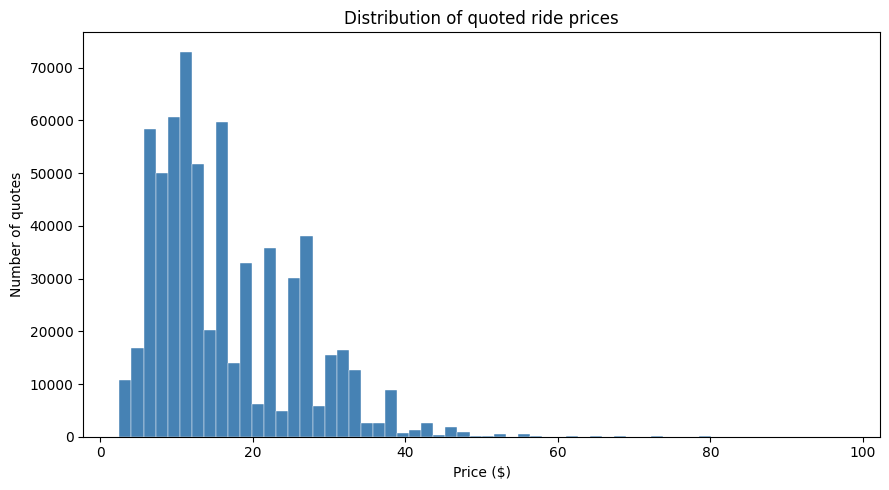

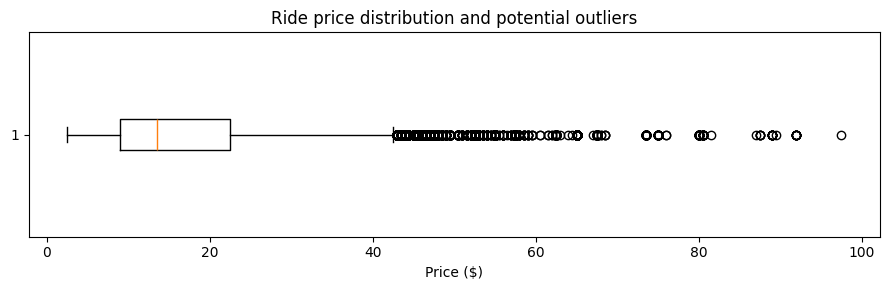

Upper IQR fence: $42.75
Observations above the upper fence: 5589

Ten highest-priced rides:
        cab_type          name  price  distance  surge_multiplier
597071     Lyft  Lux Black XL   97.5      4.43               2.0
28083      Lyft  Lux Black XL   92.0      3.89               2.0
75919      Lyft  Lux Black XL   92.0      3.75               2.0
271719     Lyft  Lux Black XL   92.0      5.39               2.0
280566     Lyft  Lux Black XL   92.0      5.39               2.0
301021     Lyft  Lux Black XL   92.0      5.36               2.0
440000     Lyft  Lux Black XL   92.0      5.37               2.0
515785     Lyft  Lux Black XL   92.0      3.75               2.0
537453     Lyft  Lux Black XL   92.0      4.39               2.0
560058     Lyft  Lux Black XL   92.0      4.37               2.0


In [ ]:
print("Price summary:\n", data["price"].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
))
print("Price skewness:", round(data["price"].skew(), 3))

plt.figure(figsize=(9, 5))
plt.hist(data["price"], bins=60, color="steelblue", edgecolor="white", linewidth=.3)
plt.title("Distribution of quoted ride prices")
plt.xlabel("Price ($)")
plt.ylabel("Number of quotes")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 3))
plt.boxplot(data["price"], vert=False)
plt.title("Ride price distribution and potential outliers")
plt.xlabel("Price ($)")
plt.tight_layout()
plt.show()

q1, q3 = data["price"].quantile([.25, .75])
upper_fence = q3 + 1.5 * (q3 - q1)
print(f"Upper IQR fence: ${upper_fence:.2f}")
print("Observations above the upper fence:", (data["price"] > upper_fence).sum())
print("\nTen highest-priced rides:\n", data.nlargest(10, "price")[[
    "cab_type", "name", "price", "distance", "surge_multiplier"
]])

#### EDA takeaway — price distribution and extreme fares

- Mean quoted fare: **$16.55**; median: **$13.50**; standard deviation: **$9.32**.
- The price distribution is **right-skewed** (skewness **1.046**) and ranges from **$2.50 to $97.50**.
- The upper 1.5×IQR fence is **$42.75**, and **5,589** quoted fares are above it. The highest examples are primarily premium **Lyft Lux Black XL** quotes with an elevated surge multiplier.

**Why it affects modeling:** A fare above a statistical outlier fence is not automatically an invalid record. These high quotes have plausible service/surge explanations, so **retain them initially**. However, a model optimized for typical fares could perform worse on expensive rides.

**Decision for the analysis:** Evaluate predictions with **MAE, RMSE, and R²**, and separately inspect prediction errors across **fare bands and ride products**. A linear-regression baseline is useful, while a tree-based model can test whether nonlinear pricing patterns improve predictions.

### 5. Compare fares across platforms and ride products

Price summary by ride product:
 cab_type         name  count  mean_price  median_price
    Lyft       Shared  51233    6.029893           7.0
    Uber     UberPool  55091    8.752500           8.5
    Lyft         Lyft  51235    9.610885           9.0
    Uber          WAV  55096    9.765019           9.5
    Uber        UberX  55094    9.765074           9.5
    Lyft      Lyft XL  51235   15.309363          13.5
    Uber       UberXL  55096   15.678144          15.0
    Lyft          Lux  51235   17.771240          16.5
    Uber        Black  55095   20.523786          19.5
    Lyft    Lux Black  51235   23.062468          22.5
    Uber    Black SUV  55096   30.286763          28.5
    Lyft Lux Black XL  51235   32.324086          30.0


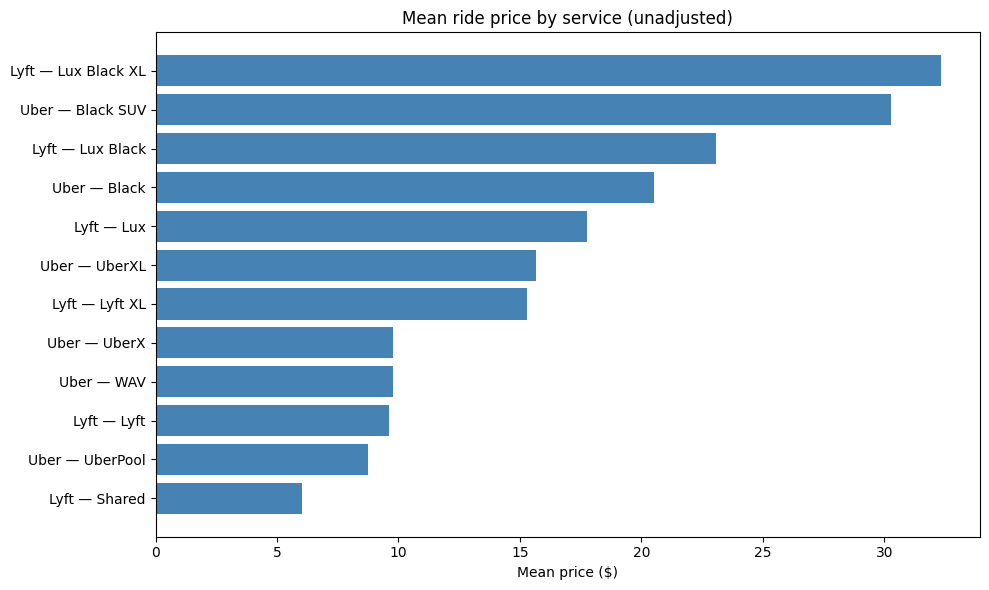

In [ ]:
product = (
    data.groupby(["cab_type", "name"], as_index=False)
        .agg(count=("price", "size"), mean_price=("price", "mean"),
             median_price=("price", "median"))
        .sort_values("mean_price")
)
print("Price summary by ride product:\n", product.to_string(index=False))

plt.figure(figsize=(10, 6))
plt.barh(product["cab_type"] + " — " + product["name"],
         product["mean_price"], color="steelblue")
plt.title("Mean ride price by service (unadjusted)")
plt.xlabel("Mean price ($)")
plt.tight_layout()
plt.show()

#### EDA takeaway — ride product as a candidate driver

The unadjusted mean fare varies substantially by product: **Lyft Shared ≈ $6.03**, **UberX ≈ $9.77**, **Uber Black ≈ $20.52**, and **Lyft Lux Black XL ≈ $32.32**. These differences are descriptive: ride distances, routes, and surge levels may also differ between groups.

**Why it affects modeling:** The service selected appears to carry important pricing information. `name` identifies the product (e.g., UberX or Lux Black XL) and already identifies its corresponding platform. Therefore, including both `name` and `cab_type` as independent features in the combined model would encode overlapping information and complicate importance interpretation.

**Decision for the analysis:** Use **`name` as a categorical predictor** in the combined model, with encoding learned from the training data. Retain **`cab_type` for separate Uber and Lyft analyses**, rather than treating it as another independent driver alongside `name`.

### 6. Explore distance and surge multiplier

Trip distance summary:
 count    637976.000000
mean          2.189261
std           1.135413
min           0.020000
25%           1.270000
50%           2.160000
75%           2.930000
max           7.860000
Name: distance, dtype: float64


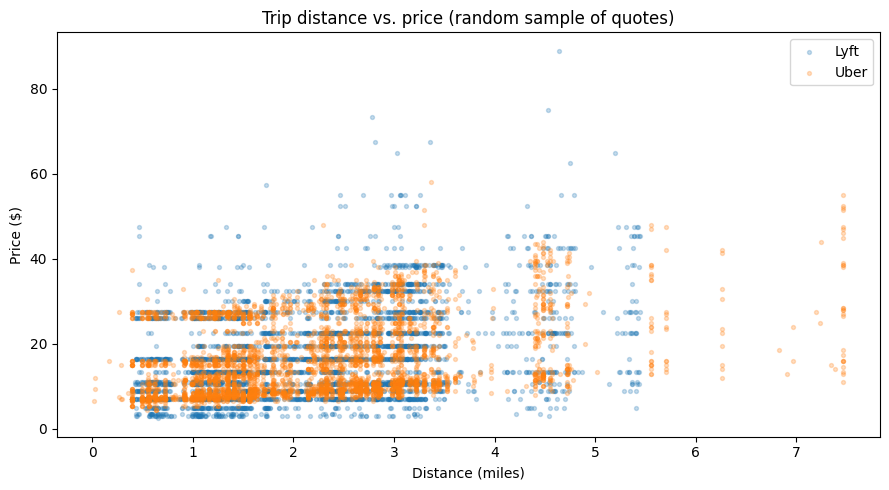


Surge multiplier by platform:
           nunique  min  max
cab_type                   
Lyft            7  1.0  3.0
Uber            1  1.0  1.0

Quotes with recorded surge > 1 by platform:
 cab_type
Lyft    20975
Name: count, dtype: int64

Lyft price summary by multiplier:
                     size       mean  median
surge_multiplier                           
1.00              286433  16.583557   16.50
1.25               11085  23.768471   22.50
1.50                5065  28.894472   26.00
1.75                2420  33.673760   30.00
2.00                2239  39.048459   38.00
2.50                 154  30.207792   27.50
3.00                  12  40.333333   38.25


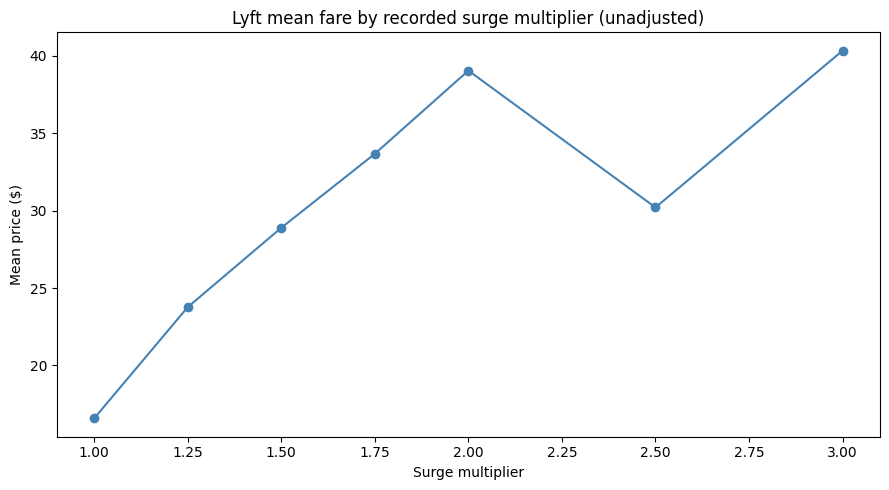

In [ ]:
print("Trip distance summary:\n", data["distance"].describe())

# Sample points for plotting speed; this does not change the dataset.
sample = data.sample(n=min(8000, len(data)), random_state=42)
plt.figure(figsize=(9, 5))
for platform, subset in sample.groupby("cab_type"):
    plt.scatter(subset["distance"], subset["price"],
                s=8, alpha=.25, label=platform)
plt.legend()
plt.title("Trip distance vs. price (random sample of quotes)")
plt.xlabel("Distance (miles)")
plt.ylabel("Price ($)")
plt.tight_layout()
plt.show()

print("\nSurge multiplier by platform:\n",
      data.groupby("cab_type")["surge_multiplier"].agg(["nunique", "min", "max"]))
print("\nQuotes with recorded surge > 1 by platform:\n",
      data.loc[data["surge_multiplier"] > 1, "cab_type"].value_counts())

lyft = data.loc[data["cab_type"] == "Lyft"]
surge = lyft.groupby("surge_multiplier")["price"].agg(["size", "mean", "median"])
print("\nLyft price summary by multiplier:\n", surge)

plt.figure(figsize=(9, 5))
plt.plot(surge.index, surge["mean"], marker="o", color="steelblue")
plt.title("Lyft mean fare by recorded surge multiplier (unadjusted)")
plt.xlabel("Surge multiplier")
plt.ylabel("Mean price ($)")
plt.tight_layout()
plt.show()

#### EDA takeaway — distance and recorded surge

- Recorded trip distances average **2.19 miles** (range: **0.02–7.86 miles**); the scatterplot suggests a generally positive association with quoted fare, but there is substantial variation at the same distance.
- `surge_multiplier` has **seven observed levels for Lyft**, but is **always 1.0 for Uber** in this file. **20,975** priced Lyft quotes have surge above 1.
- Lyft's unadjusted mean quoted fare is higher at many elevated surge levels, but very high surge values are **rare** (only **154** records at 2.5 and **12** at 3.0), so their observed means are unstable and may reflect different product mixes.

**Why it affects modeling:** Distance and surge are promising candidate drivers, but an unadjusted scatterplot or group mean does not isolate either variable's independent contribution. The lack of observed Uber surge variation is a **dataset limitation**, not evidence that Uber did not use dynamic pricing.

**Decision for the analysis:** Include **`distance`** and **`surge_multiplier`**; allow nonlinear effects to be tested with a Random Forest; and assess surge **within Lyft separately**. Avoid extrapolating from sparsely observed surge levels.

### 7. Explore time, routes, and weather

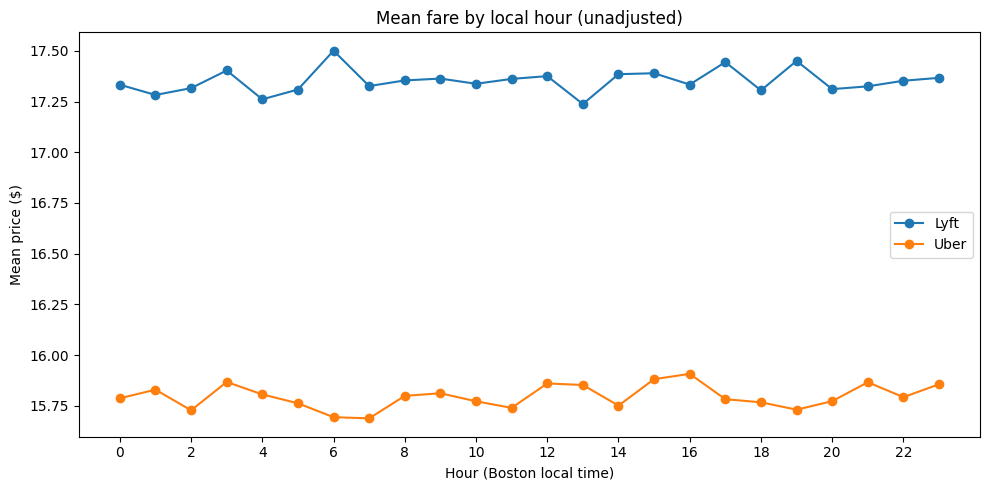


Ten routes with the highest mean price:
                  source             destination  count  mean_price  mean_distance
     Financial District       Boston University   8940   25.498434       5.172597
      Boston University      Financial District   8940   24.146085       4.544047
                 Fenway      Financial District   8916   23.438818       4.290067
     Financial District                  Fenway   8928   23.404850       4.477816
Northeastern University      Financial District   8874   22.582094       4.153469
     Financial District Northeastern University   8868   21.918584       4.020771
       Theatre District       Boston University   9173   20.360662       3.252960
      Boston University           North Station   8730   20.185338       3.431409
Northeastern University           North Station   8904   19.910939       3.222662
                 Fenway           North Station   8970   19.701839       3.152334

Price summary by weather:
                      size   

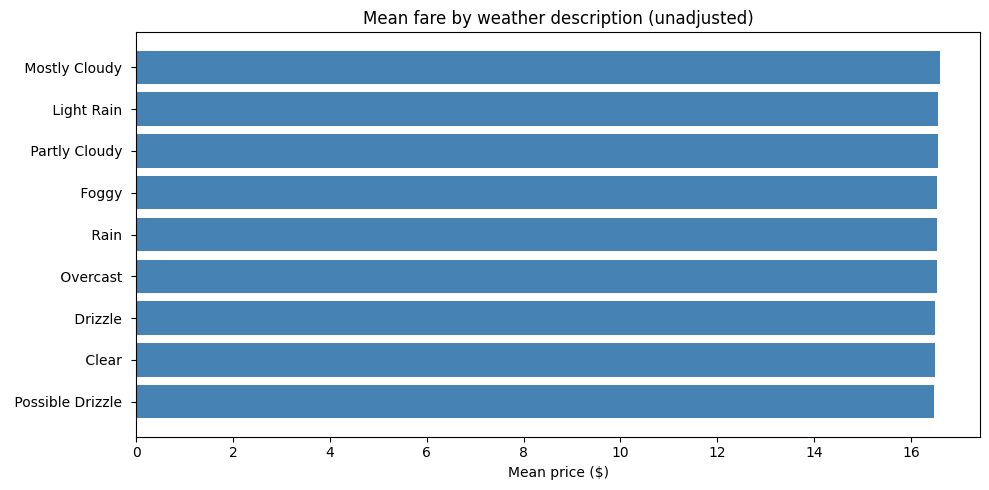

In [ ]:
hourly = data.groupby(["cab_type", "local_hour"])["price"].mean().unstack(0)
plt.figure(figsize=(10, 5))
for platform in hourly.columns:
    plt.plot(hourly.index, hourly[platform], marker="o", label=platform)
plt.legend()
plt.xticks(range(0, 24, 2))
plt.title("Mean fare by local hour (unadjusted)")
plt.xlabel("Hour (Boston local time)")
plt.ylabel("Mean price ($)")
plt.tight_layout()
plt.show()

routes = (
    data.groupby(["source", "destination"], as_index=False)
        .agg(count=("price", "size"), mean_price=("price", "mean"),
             mean_distance=("distance", "mean"))
        .sort_values("mean_price", ascending=False)
)
print("\nTen routes with the highest mean price:\n", routes.head(10).to_string(index=False))

weather = (data.groupby("short_summary")["price"]
           .agg(["size", "mean"]).sort_values("mean"))
print("\nPrice summary by weather:\n", weather)

plt.figure(figsize=(10, 5))
plt.barh(weather.index, weather["mean"], color="steelblue")
plt.title("Mean fare by weather description (unadjusted)")
plt.xlabel("Mean price ($)")
plt.tight_layout()
plt.show()

#### EDA takeaway — location, time, and weather

- The local-hour fare curves are fairly flat within each platform, so there is no large **unadjusted** time-of-day pattern in this sample.
- More expensive observed origin–destination pairs are also generally longer trips. For example, **Financial District → Boston University** averages about **$25.50**, with mean distance **5.17 miles**. Route and distance therefore overlap conceptually.
- Weather-condition mean fares are close together: about **$16.48** for **Possible Drizzle** versus **$16.59** for **Mostly Cloudy**. This does not suggest a large *unadjusted* weather difference.

**Why it affects modeling:** Small differences in group averages do not rule out interactions or conditional effects. At the same time, route information and distance may provide overlapping signals, so their individual importance requires care.

**Decision for the analysis:** Retain **`source`**, **`destination`**, **`local_hour`**, and **`weekday`** as exploratory controls. Include a compact numeric weather set—**`temperature`**, **`precipIntensity`**, and **`windSpeed`**—to *test* whether weather contributes once service, distance, surge, and route are accounted for. Do not claim weather has zero impact from descriptive averages alone.

### 8. Numeric correlations and possible redundant predictors

Numerical variables summary:
                         count       mean       std     min     25%    50%  \
price                637976.0  16.545125  9.324359   2.500   9.000  13.50   
distance             637976.0   2.189261  1.135413   0.020   1.270   2.16   
surge_multiplier     637976.0   1.015068  0.095422   1.000   1.000   1.00   
temperature          637976.0  39.582406  6.725500  18.910  36.450  40.49   
apparentTemperature  637976.0  35.878440  7.917260  12.130  31.910  35.90   
precipIntensity      637976.0   0.008909  0.026880   0.000   0.000   0.00   
precipProbability    637976.0   0.145941  0.328776   0.000   0.000   0.00   
humidity             637976.0   0.741056  0.138575   0.380   0.640   0.71   
windSpeed            637976.0   6.186795  3.147856   0.450   3.410   5.91   
windGust             637976.0   8.470616  5.288683   0.800   4.060   7.55   
visibility           637976.0   8.469180  2.601828   0.717   8.432   9.88   

                        75%      max  
price 

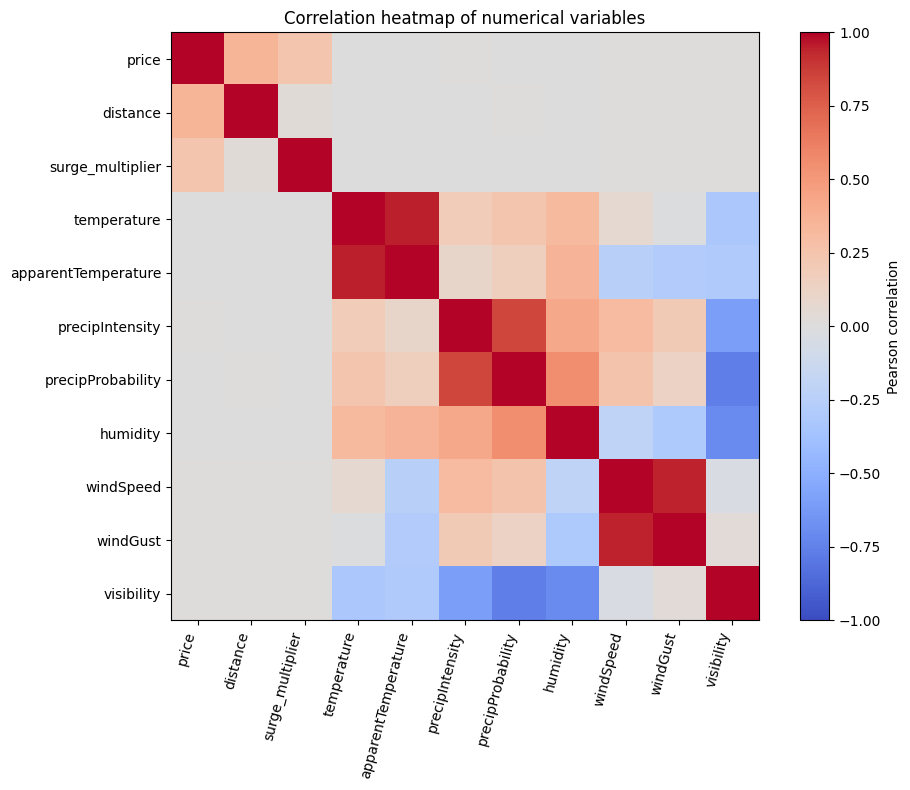


Ride products by platform:
 cab_type       Lyft   Uber
name                      
Black             0  55095
Black SUV         0  55096
Lux           51235      0
Lux Black     51235      0
Lux Black XL  51235      0
Lyft          51235      0
Lyft XL       51235      0
Shared        51233      0
UberPool          0  55091
UberX             0  55094
UberXL            0  55096
WAV               0  55096

EDA complete. Correlations and unadjusted group means are NOT key-driver importance scores.


In [ ]:
numeric = [
    "price", "distance", "surge_multiplier", "temperature", "apparentTemperature",
    "precipIntensity", "precipProbability", "humidity", "windSpeed", "windGust", "visibility"
]
print("Numerical variables summary:\n", data[numeric].describe().T)

corr = data[numeric].corr()
print("\nPearson correlations with price:\n",
      corr["price"].sort_values(ascending=False).round(3))

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric)), numeric, rotation=75, ha="right")
ax.set_yticks(range(len(numeric)), numeric)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation heatmap of numerical variables")
plt.tight_layout()
plt.show()

print("\nRide products by platform:\n", pd.crosstab(data["name"], data["cab_type"]))
print("\nEDA complete. Correlations and unadjusted group means are NOT key-driver importance scores.")

#### EDA takeaway — correlation and redundancy

The largest marginal **Pearson correlations with price** among the displayed numerical variables are **distance (0.345)** and **surge multiplier (0.240)**. The weather correlations with price are close to zero. Pearson correlation measures a **pairwise linear association**; it does not measure conditional importance, nonlinear relationships, or causal effects.

The heatmap also motivates avoiding multiple highly related weather measures in the first model (such as `temperature` and `apparentTemperature`, or `windSpeed` and `windGust`). The cross-tab confirms that product `name` uniquely maps to Uber or Lyft in the observed data.

**Decision for the analysis:** Begin with a **small, interpretable candidate set** and compare a multiple linear regression baseline with a Random Forest. Estimate the final importance *after* a held-out evaluation using **permutation importance**. Validate the ranking through robustness checks and feature-group ablation, especially for related route and distance predictors.

## 9. EDA synthesis — turning observations into a modeling plan

The goal is **not** to select only variables with large unadjusted correlations. Instead, we will test plausible predictors together to see what each one adds after accounting for the others.

| Candidate variable(s) | Evidence from EDA | Initial decision / rationale |
|---|---|---|
| **`name`** (ride product) | Wide differences in average fare across service tiers | **Include.** One-hot encode in Python; also captures platform identity, so omit `cab_type` from the combined-model predictor list. |
| **`distance`** | Positive price association; wide spread at a given distance | **Include.** Test for nonlinear effects. |
| **`surge_multiplier`** | Higher Lyft prices often accompany higher recorded multipliers | **Include.** Interpret cautiously; Uber values are constant and rare Lyft high-surge levels are sparse. |
| **`source`, `destination`** | Route average prices differ, but longer routes cost more | **Include initially.** Evaluate whether they add value beyond `distance`; keep route/distance overlap in mind. |
| **`local_hour`, `weekday`** | Weak raw hourly differences | **Include initially.** Treat as time categories and test incremental predictive value. |
| **`temperature`, `precipIntensity`, `windSpeed`** | Weak raw fare associations for measured weather | **Include a small representative set.** Test conditional effects rather than excluding weather a priori. |
| **`cab_type`** | Product name already identifies platform | **Exclude as a separate predictor in the combined model;** use to create Uber-only and Lyft-only comparisons. |
| **`id`, `product_id`, redundant weather measures, daily-extrema timestamps** | Identifiers / overlapping information / potential timing leakage | **Exclude from initial modeling.** Preserve only fields needed to process and audit records. |


### Scope and limitations to carry forward

These are **historical Boston-area fare quotes from late 2018**, not observed final payments or contemporary prices. Service and route variables overlap with other predictors, Uber surge has no variation in the file, and price differences do not establish causation. The follow-up work should evaluate how much each variable contributes *conditional on the modeling choices and observed data*.

**EDA conclusion:** The descriptive evidence makes **ride product, trip distance, and recorded surge** the leading candidates to investigate, while **route, time, and weather** remain useful hypotheses to test. The next stage is SQL preprocessing, followed by multivariable key-driver modeling—not a conclusion that the drivers have already been proved important by EDA.